In [1]:
from pathlib import Path
import pandas as pd
from astroquery.utils.tap import TapPlus

# Project paths
ROOT = Path.cwd()
DATA_RAW = ROOT / "data" / "raw"
NASA_RAW = DATA_RAW / "nasa"
FULTON_RAW = DATA_RAW / "fulton"
CKS_RAW = DATA_RAW / "cks"

for folder in [NASA_RAW, FULTON_RAW, CKS_RAW]:
    folder.mkdir(parents=True, exist_ok=True)

print("NASA :", NASA_RAW.resolve())
print("Fulton:", FULTON_RAW.resolve())
print("CKS  :", CKS_RAW.resolve())

NASA : C:\Users\Lenovo\Downloads\Binary_Gap\data\raw\nasa
Fulton: C:\Users\Lenovo\Downloads\Binary_Gap\data\raw\fulton
CKS  : C:\Users\Lenovo\Downloads\Binary_Gap\data\raw\cks


In [2]:
# !pip install astroquery
# 

In [3]:
query = """
SELECT *
FROM q1_q17_dr25_koi
"""
tap = TapPlus(
    url="https://exoplanetarchive.ipac.caltech.edu/TAP"
)
print("Downloading full Kepler DR25 KOI catalogue...")

job = tap.launch_job_async(query, verbose=True)
dr25 = job.get_results().to_pandas()

output_file = NASA_RAW / "nasa_kepler_dr25_koi.csv"
dr25.to_csv(output_file, index=False)

print(f"Rows    : {len(dr25):,}")
print(f"Columns : {len(dr25.columns):,}")
print(f"Saved   : {output_file.resolve()}")

display(
    dr25[
        [
            "kepoi_name", "kepid", "koi_period", "koi_prad",
            "koi_prad_err1", "koi_prad_err2",
            "koi_steff", "koi_smass", "koi_srad"
        ]
    ].head()
)

Launched query: '
SELECT *
FROM q1_q17_dr25_koi
'
------>https
host = exoplanetarchive.ipac.caltech.edu:443
context = /TAP/async
Content-type = application/x-www-form-urlencoded
303 See Other
[('Date', 'Sun, 25 Oct 2026 18:24:42 GMT'), ('Transfer-Encoding', 'chunked'), ('Connection', 'keep-alive'), ('Server', 'cloudflare'), ('Location', 'https://exoplanetarchive.ipac.caltech.edu//TAP/async/tap_atpb99ra'), ('cf-cache-status', 'DYNAMIC'), ('CF-RAY', 'a5034271390f46ef-BOM')]
job tap_atpb99ra, at: https://exoplanetarchive.ipac.caltech.edu//TAP/async/tap_atpb99ra
Retrieving async. results...
INFO: Query finished. [astroquery.utils.tap.core]
Rows    : 8,054
Columns : 153
Saved   : C:\Users\Lenovo\Downloads\Binary_Gap\data\raw\nasa\nasa_kepler_dr25_koi.csv


,kepoi_name,kepid,koi_period,koi_prad,koi_prad_err1,koi_prad_err2,koi_steff,koi_smass,koi_srad
0,K00753.01,10811496,19.899140,14.60,3.92,-1.31,5853.0,0.961,0.868
1,K00754.01,10848459,1.736952,33.46,8.50,-2.83,5805.0,0.836,0.791
2,K00755.01,10854555,2.525592,2.75,0.88,-0.35,6031.0,1.095,1.046
3,K00756.01,10872983,11.094321,3.90,1.27,-0.42,6046.0,1.053,0.972
4,K00756.02,10872983,4.134435,2.77,0.90,-0.30,6046.0,1.053,0.972


In [4]:
print("Shape:", dr25.shape)
print("Duplicate KOI names:", dr25["kepoi_name"].duplicated().sum())

print("\nMissing values in key columns:")
display(
    dr25[
        [
            "kepoi_name",
            "koi_period",
            "koi_prad",
            "koi_prad_err1",
            "koi_prad_err2",
            "koi_steff",
            "koi_smass",
            "koi_srad",
        ]
    ].isna().sum().to_frame("missing")
)

print("\nDisposition counts:")
display(dr25["koi_disposition"].value_counts(dropna=False))

Shape: (8054, 153)
Duplicate KOI names: 0

Missing values in key columns:


,missing
kepoi_name,0
koi_period,0
koi_prad,59
koi_prad_err1,59
koi_prad_err2,59
koi_steff,59
koi_smass,59
koi_srad,59



Disposition counts:


koi_disposition
FALSE POSITIVE    3965
CONFIRMED         2731
CANDIDATE         1358
Name: count, dtype: int64

In [5]:
import requests
import warnings
from astropy.io import ascii
from astropy.table import Table
from astropy.units import UnitsWarning

def download_file(url, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists() and destination.stat().st_size > 0:
        print(f"Cached: {destination.name}")
        return destination

    response = requests.get(url, timeout=180)
    response.raise_for_status()
    destination.write_bytes(response.content)

    print(f"Downloaded: {destination.name}")
    return destination

In [6]:
cks_dir = CKS_RAW / "J_AJ_154_108"
base = "https://cdsarc.cds.unistra.fr/ftp/cats/J/AJ/154/108"

for filename in ["table1.dat", "table4.dat", "ReadMe"]:
    download_file(base + "/" + filename, cks_dir / filename)

# Download the VizieR version of Table 4, which includes Star associations
vizier_url = (
    "https://vizier.cds.unistra.fr/viz-bin/votable"
    "?-source=J/AJ/154/108/table4"
)

download_file(vizier_url, cks_dir / "table4_vizier.vot")

Downloaded: table1.dat
Downloaded: table4.dat
Downloaded: ReadMe
Downloaded: table4_vizier.vot


WindowsPath('C:/Users/Lenovo/Downloads/Binary_Gap/data/raw/cks/J_AJ_154_108/table4_vizier.vot')

In [7]:
fulton17_dir = FULTON_RAW / "J_AJ_154_109"
base = "https://cdsarc.cds.unistra.fr/ftp/cats/J/AJ/154/109"

for filename in ["table2.dat", "ReadMe"]:
    download_file(base + "/" + filename, fulton17_dir / filename)

Downloaded: table2.dat
Downloaded: ReadMe


In [8]:
fulton18_dir = FULTON_RAW / "J_AJ_156_264"
base = "https://cdsarc.cds.unistra.fr/ftp/cats/J/AJ/156/264"

for filename in ["table2.dat", "table3.dat", "table4.dat", "ReadMe"]:
    download_file(base + "/" + filename, fulton18_dir / filename)

Downloaded: table2.dat
Downloaded: table3.dat
Downloaded: table4.dat
Downloaded: ReadMe


In [10]:
query = """
SELECT
    pl_name,
    hostname,
    disc_facility,
    pl_rade,
    pl_radeerr1,
    pl_radeerr2,
    pl_orbper
FROM pscomppars
WHERE pl_rade IS NOT NULL
"""

print("Downloading confirmed planets...")

job = tap.launch_job_async(query, verbose=True)
confirmed = job.get_results().to_pandas()

confirmed_file = NASA_RAW / "confirmed_planets_pscomppars.csv"
confirmed.to_csv(confirmed_file, index=False)

print("Shape:", confirmed.shape)
print("Saved:", confirmed_file.resolve())

Launched query: '
SELECT
    pl_name,
    hostname,
    disc_facility,
    pl_rade,
    pl_radeerr1,
    pl_radeerr2,
    pl_orbper
FROM pscomppars
WHERE pl_rade IS NOT NULL
'
------>https
host = exoplanetarchive.ipac.caltech.edu:443
context = /TAP/async
Content-type = application/x-www-form-urlencoded
303 See Other
[('Date', 'Sun, 25 Oct 2026 18:25:56 GMT'), ('Transfer-Encoding', 'chunked'), ('Connection', 'keep-alive'), ('Server', 'cloudflare'), ('Location', 'https://exoplanetarchive.ipac.caltech.edu//TAP/async/tap_4vz30daz'), ('cf-cache-status', 'DYNAMIC'), ('CF-RAY', 'a50344417d6d32a3-BOM')]
job tap_4vz30daz, at: https://exoplanetarchive.ipac.caltech.edu//TAP/async/tap_4vz30daz
Retrieving async. results...
INFO: Query finished. [astroquery.utils.tap.core]
Shape: (6401, 7)
Saved: C:\Users\Lenovo\Downloads\Binary_Gap\data\raw\nasa\confirmed_planets_pscomppars.csv


In [11]:
def read_cds_table(folder, filename):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UnitsWarning)
        table = ascii.read(
            folder / filename,
            format="cds",
            readme=folder / "ReadMe"
        )
    return table.to_pandas()


cks17_stars = read_cds_table(cks_dir, "table1.dat")
cks17_planets = read_cds_table(cks_dir, "table4.dat")

fulton17 = read_cds_table(fulton17_dir, "table2.dat")

fulton18_stars = read_cds_table(fulton18_dir, "table2.dat")
fulton18_planets = read_cds_table(fulton18_dir, "table3.dat")
fulton18_detection = read_cds_table(fulton18_dir, "table4.dat")

# Read the VizieR CKS Table 4 separately
cks17_planets_vizier = Table.read(
    cks_dir / "table4_vizier.vot",
    format="votable"
).to_pandas()

print("CKS 2017 stars:", cks17_stars.shape)
print("CKS 2017 planets (CDS):", cks17_planets.shape)
print("CKS 2017 planets (VizieR):", cks17_planets_vizier.shape)
print("Fulton 2017:", fulton17.shape)
print("Fulton 2018 stars:", fulton18_stars.shape)
print("Fulton 2018 planets:", fulton18_planets.shape)
print("Fulton 2018 detection table:", fulton18_detection.shape)

CKS 2017 stars: (1305, 28)
CKS 2017 planets (CDS): (2025, 15)
CKS 2017 planets (VizieR): (2025, 12)
Fulton 2017: (900, 12)
Fulton 2018 stars: (1189, 31)
Fulton 2018 planets: (1901, 16)
Fulton 2018 detection table: (907, 5)


DR25 (candidates + confirmed)   : N = 3,474
CKS 2017                        : N = 1,690
Fulton 2017                     : N =   853
Fulton & Petigura 2018          : N = 1,608
Confirmed Kepler                : N = 2,479


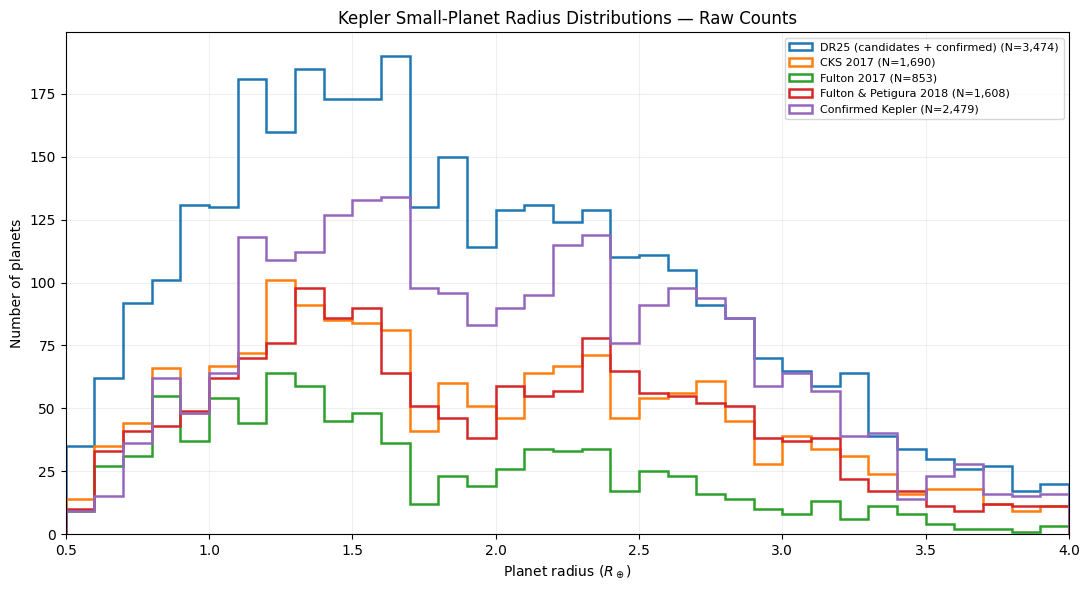

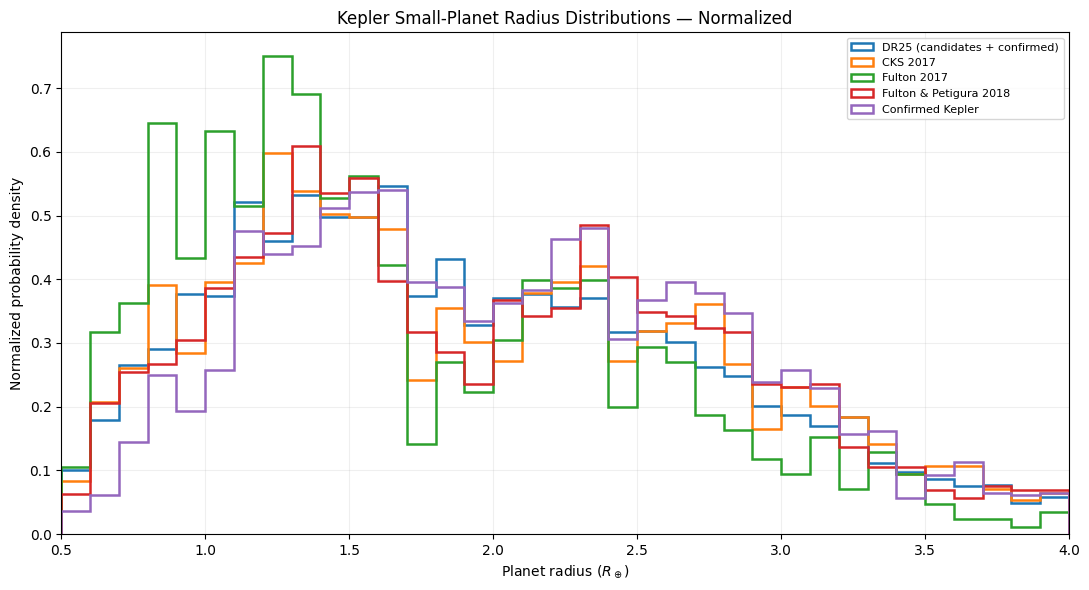

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R_MIN, R_MAX = 0.5, 4.0
RADIUS_BINS = np.linspace(R_MIN, R_MAX, 36)


def get_column(df, candidates):
    """Find a column without worrying about capitalization or spaces."""
    columns = {str(c).strip().lower(): c for c in df.columns}

    for name in candidates:
        if name.lower() in columns:
            return pd.to_numeric(
                df[columns[name.lower()]], errors="coerce"
            )

    raise KeyError(
        f"Could not find {candidates}. Available columns: {list(df.columns)}"
    )


# Prepare the radius arrays
dr25_plot = dr25.copy()
dr25_plot = dr25_plot[
    dr25_plot["koi_disposition"].isin(["CANDIDATE", "CONFIRMED"])
]
dr25_radius = get_column(dr25_plot, ["koi_prad"])

cks_radius = get_column(cks17_planets_vizier, ["Rad"])
fulton17_radius = get_column(fulton17, ["Rad"])
fulton18_radius = get_column(fulton18_planets, ["Rp"])
confirmed_radius = get_column(confirmed, ["pl_rade"])

# Keep only the Kepler-discovered confirmed planets
kepler_mask = confirmed["disc_facility"].astype(str).str.contains(
    "Kepler", case=False, na=False
)
confirmed_radius = confirmed_radius[kepler_mask]


datasets = {
    "DR25 (candidates + confirmed)": dr25_radius,
    "CKS 2017": cks_radius,
    "Fulton 2017": fulton17_radius,
    "Fulton & Petigura 2018": fulton18_radius,
    "Confirmed Kepler": confirmed_radius,
}

# Apply the same radius window for this verification plot
cleaned = {}

for name, radius in datasets.items():
    radius = radius.dropna()
    radius = radius[
        np.isfinite(radius)
        & (radius >= R_MIN)
        & (radius <= R_MAX)
    ]
    cleaned[name] = radius.to_numpy()

    print(f"{name:32s}: N = {len(radius):5,}")


# Plot 1: Raw counts
fig, ax = plt.subplots(figsize=(11, 6))

for name, radius in cleaned.items():
    ax.hist(
        radius,
        bins=RADIUS_BINS,
        histtype="step",
        linewidth=1.8,
        label=f"{name} (N={len(radius):,})",
    )

ax.set(
    xlim=(R_MIN, R_MAX),
    xlabel=r"Planet radius ($R_\oplus$)",
    ylabel="Number of planets",
    title="Kepler Small-Planet Radius Distributions — Raw Counts",
)
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# Plot 2: Normalized distributions
fig, ax = plt.subplots(figsize=(11, 6))

for name, radius in cleaned.items():
    if len(radius) > 0:
        ax.hist(
            radius,
            bins=RADIUS_BINS,
            density=True,
            histtype="step",
            linewidth=1.8,
            label=name,
        )

ax.set(
    xlim=(R_MIN, R_MAX),
    xlabel=r"Planet radius ($R_\oplus$)",
    ylabel="Normalized probability density",
    title="Kepler Small-Planet Radius Distributions — Normalized",
)
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


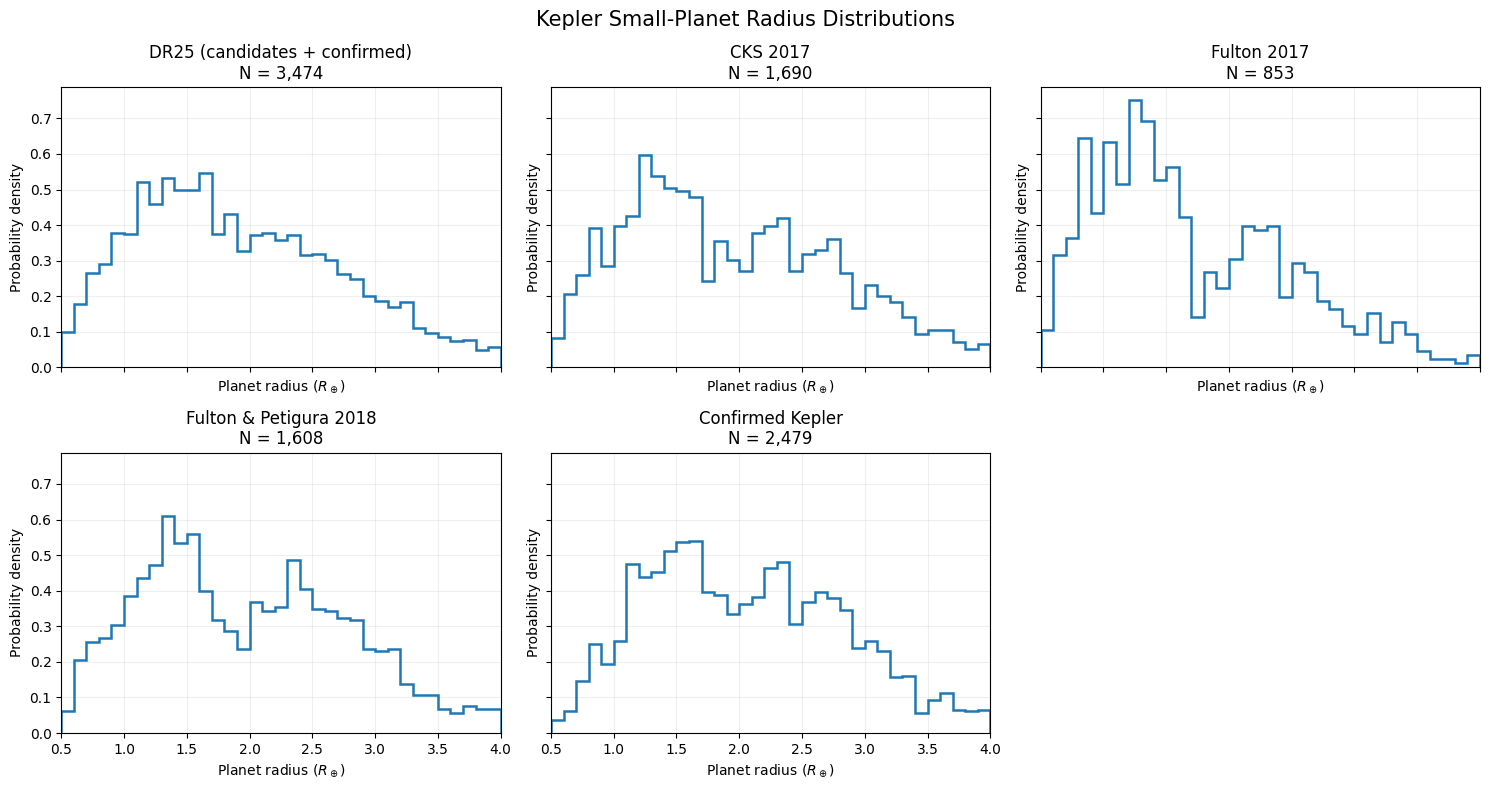

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (name, radius) in zip(axes, cleaned.items()):
    ax.hist(
        radius,
        bins=RADIUS_BINS,
        density=True,
        histtype="step",
        linewidth=1.8
    )

    ax.set_title(f"{name}\nN = {len(radius):,}")
    ax.set_xlim(R_MIN, R_MAX)
    ax.set_xlabel(r"Planet radius ($R_\oplus$)")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.2)

# Hide the unused sixth panel
axes[-1].set_visible(False)

fig.suptitle(
    "Kepler Small-Planet Radius Distributions",
    fontsize=15
)
plt.tight_layout()
plt.show()

DR25 (candidate + confirmed)    : N = 2,852
CKS 2017                        : N = 1,576
Fulton 2017                     : N = 853
Fulton & Petigura 2018          : N = 1,472
Confirmed Kepler                : N = 2,369


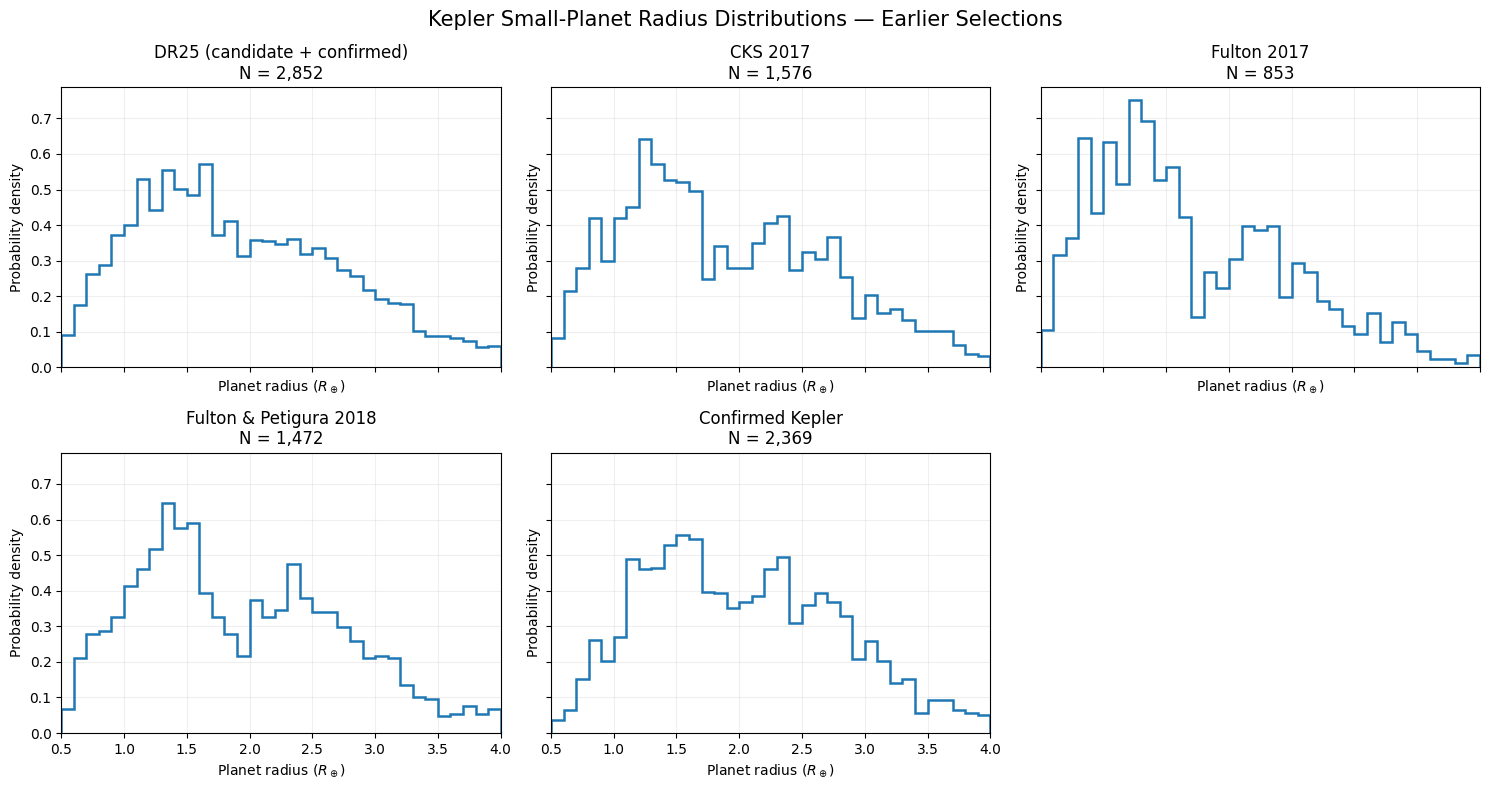

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R_MIN, R_MAX = 0.5, 4.0
PERIOD_MAX = 100.0
TEFF_MIN, TEFF_MAX = 4700.0, 6500.0
RADIUS_BINS = np.linspace(R_MIN, R_MAX, 36)


def get_column(df, candidates):
    columns = {str(c).strip().lower(): c for c in df.columns}

    for name in candidates:
        if name.lower() in columns:
            return pd.to_numeric(
                df[columns[name.lower()]], errors="coerce"
            )

    raise KeyError(f"Missing columns {candidates}")


def select_radius_period(df, radius_col, period_col):
    radius = get_column(df, [radius_col])
    period = get_column(df, [period_col])

    mask = (
        radius.between(R_MIN, R_MAX)
        & period.gt(0)
        & period.le(PERIOD_MAX)
    )

    return radius[mask].to_numpy()


# 1. DR25: candidates + confirmed, radius/period/Teff cuts,
#    and finite fractional radius uncertainty
dr_radius = get_column(dr25, ["koi_prad"])
dr_period = get_column(dr25, ["koi_period"])
dr_teff = get_column(dr25, ["koi_steff"])

sigma_radius = 0.5 * (
    get_column(dr25, ["koi_prad_err1"]).abs()
    + get_column(dr25, ["koi_prad_err2"]).abs()
)

frac_err = sigma_radius / dr_radius.where(dr_radius > 0)

disposition = dr25["koi_disposition"].astype(str).str.upper().str.strip()

dr_mask = (
    disposition.isin(["CANDIDATE", "CONFIRMED"])
    & dr_radius.between(R_MIN, R_MAX)
    & dr_period.gt(0)
    & dr_period.le(PERIOD_MAX)
    & dr_teff.between(TEFF_MIN, TEFF_MAX)
    & np.isfinite(frac_err)
)

dr25_selected = dr_radius[dr_mask].to_numpy()


# 2. CKS 2017: radius and period cuts
# The earlier run failed to join stellar Teff for this catalogue,
# so it did not apply a Teff cut.
cks_selected = select_radius_period(
    cks17_planets_vizier, "Rad", "Per"
)


# 3. Fulton 2017 detections: radius and period cuts
fulton17_selected = select_radius_period(
    fulton17, "Rad", "Per"
)


# 4. Fulton & Petigura 2018: radius, period, and stellar Teff cuts
def host_number(series):
    text = series.astype(str).str.extract(
        r"(\d+(?:\.\d+)?)", expand=False
    )
    return np.floor(
        pd.to_numeric(text, errors="coerce")
    )


f18_planets = fulton18_planets.copy()
f18_stars = fulton18_stars.copy()

f18_planets["host_id"] = host_number(f18_planets["KOI"])
f18_stars["host_id"] = host_number(f18_stars["KOI"])
f18_stars["Teff"] = get_column(f18_stars, ["Teff"])

teff_lookup = (
    f18_stars.dropna(subset=["host_id"])
    .drop_duplicates("host_id")
    .set_index("host_id")["Teff"]
)

f18_planets["teff_star"] = f18_planets["host_id"].map(teff_lookup)

f18_radius = get_column(f18_planets, ["Rp"])
f18_period = get_column(f18_planets, ["Per"])
f18_teff = f18_planets["teff_star"]

f18_mask = (
    f18_radius.between(R_MIN, R_MAX)
    & f18_period.gt(0)
    & f18_period.le(PERIOD_MAX)
    & f18_teff.between(TEFF_MIN, TEFF_MAX)
)

fulton18_selected = f18_radius[f18_mask].to_numpy()


# 5. Confirmed Kepler planets: radius and period cuts
confirmed_kepler = confirmed[
    confirmed["disc_facility"].astype(str).str.contains(
        "Kepler", case=False, na=False
    )
].copy()

confirmed_selected = select_radius_period(
    confirmed_kepler, "pl_rade", "pl_orbper"
)


# Summarize sample sizes before plotting
cleaned = {
    "DR25 (candidate + confirmed)": dr25_selected,
    "CKS 2017": cks_selected,
    "Fulton 2017": fulton17_selected,
    "Fulton & Petigura 2018": fulton18_selected,
    "Confirmed Kepler": confirmed_selected,
}

for name, radius in cleaned.items():
    print(f"{name:32s}: N = {len(radius):,}")


# Plot in a 2 x 3 subplot layout
fig, axes = plt.subplots(
    2, 3, figsize=(15, 8), sharex=True, sharey=True
)
axes = axes.flatten()

for ax, (name, radius) in zip(axes, cleaned.items()):
    ax.hist(
        radius,
        bins=RADIUS_BINS,
        density=True,
        histtype="step",
        linewidth=1.8,
    )
    ax.set_title(f"{name}\nN = {len(radius):,}")
    ax.set_xlim(R_MIN, R_MAX)
    ax.set_xlabel(r"Planet radius ($R_\oplus$)")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.2)

axes[-1].set_visible(False)

fig.suptitle(
    "Kepler Small-Planet Radius Distributions — Earlier Selections",
    fontsize=15
)
plt.tight_layout()
plt.show()